In [33]:
import pandas as pd
import joblib
import shap

# Load data
df = pd.read_csv("../data/processed/phase2_feature_complete.csv")

# Load model
xgb_model = joblib.load("../models/xgb_price_model.pkl")


In [34]:
le_district = joblib.load("../models/district_encoder.pkl")
le_commodity = joblib.load("../models/commodity_encoder.pkl")


In [35]:
df['district_enc']  = le_district.transform(df['district'])
df['commodity_enc'] = le_commodity.transform(df['commodity'])

In [36]:
drop_cols = ['date', 'modal_price', 'district', 'commodity']
X = df.drop(columns=drop_cols)
y = df['modal_price']


In [37]:
X.columns.tolist()


['min_price',
 'max_price',
 'temp_max',
 'temp_min',
 'rainfall',
 'wind_speed',
 'modal_price_lag_1',
 'modal_price_lag_7',
 'modal_price_lag_14',
 'district_enc',
 'commodity_enc']

In [38]:
def xgb_predict(X):
    return xgb_model.predict(X)


In [39]:
X_background = X.sample(1000, random_state=42)
X_explain    = X.sample(1000, random_state=1)

explainer = shap.Explainer(
    xgb_predict,
    X_background,
    algorithm="permutation"   # important
)

In [40]:
shap_values = explainer(X_explain)

PermutationExplainer explainer: 1001it [02:15,  6.85it/s]                          


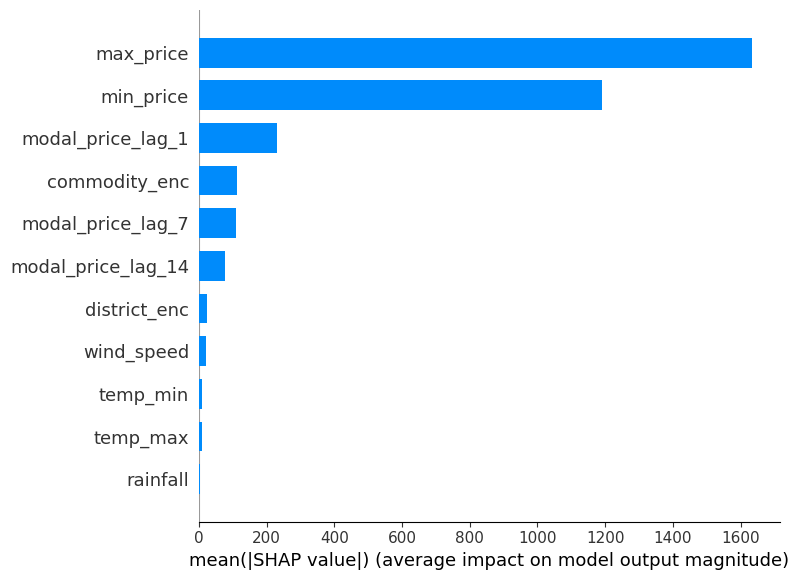

In [41]:
shap.summary_plot(shap_values, X_explain, plot_type="bar")


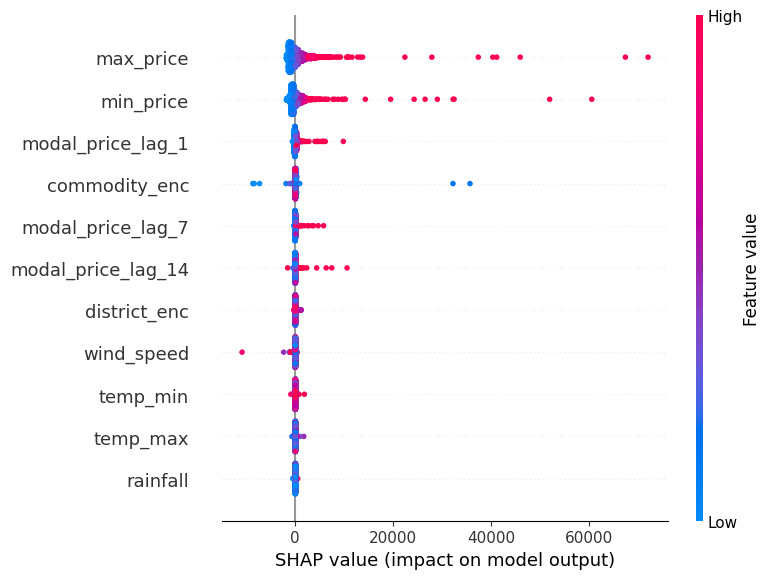

In [42]:
shap.summary_plot(shap_values, X_explain)


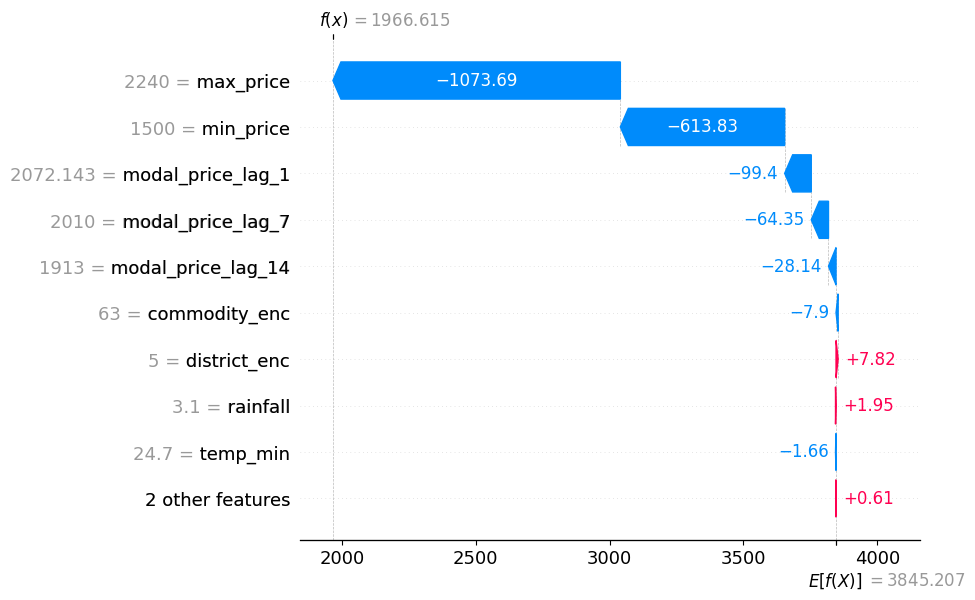

In [43]:
shap.plots.waterfall(shap_values[0])


In [45]:
import numpy as np

commodity_name = "Tomato"
cid = le_commodity.transform([commodity_name])[0]

idx = np.where(X_explain['commodity_enc'].values == cid)[0]


In [46]:
len(idx)



27

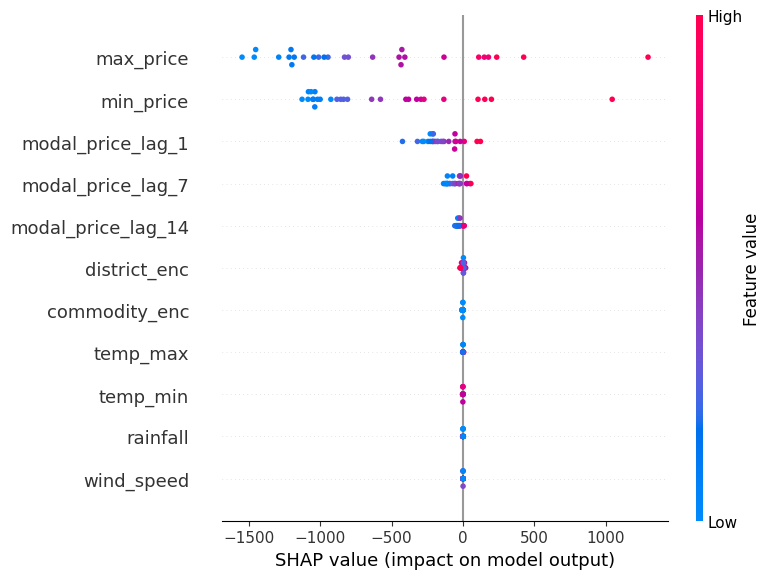

In [47]:
shap.summary_plot(
    shap_values[idx],
    X_explain.iloc[idx],
    show=True
)
